# Household Energy Forecasting & Anomaly Detection (Pakistan, REWDP)

**Pipeline:** repair timestamps → clean sensor downtime → hourly features → baselines vs ML (RF, LightGBM, LSTM) → day-ahead forecasting → anomaly detection → multi-house evaluation → weather experiment.

**Key design decisions**

| Area | Decision |
|---|---|
| Timestamps | Rows sharing an identical timestamp are numbered as consecutive seconds, so no row is lost |
| Downtime | Runs of >= 10 exact zeros are set to NaN; long gaps stay NaN and are excluded from training and scoring |
| Leakage | Rolling features are computed on `shift(1)` so the current hour is never used |
| Split | 70 / 10 / 20 chronological (train / validation / test), same rows for every model |
| Baselines | Persistence (t-1h) and seasonal naive (t-24h, t-168h) |
| Target | Models predict the change from the last known value ("delta"), not the raw usage |
| Anomalies | Relative residual with a robust (MAD) threshold fitted on validation, k = 5 |

In [2]:
import re, random, traceback, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.preprocessing import MinMaxScaler
from lightgbm import LGBMRegressor

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid")


SEED = 42
random.seed(SEED); np.random.seed(SEED)

DATA_ROOT    = "/kaggle/input/datasets/azizullahasad/rewp-ai-project/rewdp_dataset_small/rewdp_dataset"
WEATHER_ROOT = "/kaggle/input/datasets/azizullahasad/rewd-weather-dataset/weather_dataset"

HOUSES = {
    "Karachi":   [38, 39, 40],
    "Lahore":    [7, 8, 9],
    "Peshawar":  [26, 29, 30],
    "Multan":    [18, 19, 20],
    "Skardu":    [56, 57, 59],
    "Islamabad": [48, 49, 50],
}
def house_path(city, n):
    return f"{DATA_ROOT}/{city}/{city.lower()}_House{n}.csv"

try:
    import tensorflow as tf
    tf.keras.utils.set_random_seed(SEED)
    HAS_TF = True
except ImportError:
    HAS_TF = False
    print("TensorFlow not found - LSTM section will be skipped.")

## 1. Load and repair

Issues found in the raw files:

1. **Midnight rows lose their time** (`2023-09-03` instead of `2023-09-03 00:00:00`). `pd.to_datetime(..., format="mixed")` parses these as 00:00.
2. **Repeated timestamps.** In House 38, 23,338 rows share identical timestamps. They are numbered as consecutive seconds. (Numbering them as minutes made rows collide and about 23k rows were dropped.)
3. **Sensor downtime:** long runs of exact `0.0` kW in `Usage` are missing data, not real consumption, and must not be interpolated across days.

In [3]:
def standardize_columns(df):
    """Handle files that use 'Usage..kW.'-style headers."""
    ren = {c: "Usage (kW)" for c in df.columns if c.lower().startswith("usage")}
    return df.rename(columns=ren)


def repair_timestamps(raw_ts):
    """Parse mixed-format timestamps. Rows sharing an identical timestamp
    are numbered as consecutive minutes (fixes the hour-truncated block)."""
    ts = pd.to_datetime(raw_ts, format="mixed")
    run_id  = (ts != ts.shift()).cumsum()
    run_len = ts.groupby(run_id).transform("size")
    offset  = ts.groupby(run_id).cumcount().where(run_len > 1, 0)
    return ts + pd.to_timedelta(offset, unit="s"), int((run_len > 1).sum())

In [4]:
def load_house(path, zero_run_min=10, min_coverage=0.5, hour_gap_limit=3):
    raw = standardize_columns(pd.read_csv(path))
    ts, n_repaired = repair_timestamps(raw["datetime"])

    df = raw.drop(columns="datetime").apply(pd.to_numeric, errors="coerce")
    df.index = pd.DatetimeIndex(ts, name="datetime")
    df = df.sort_index()

    n_dup = int(df.index.duplicated().sum())
    df = df[~df.index.duplicated(keep="first")]

    is_zero = df["Usage (kW)"].eq(0)
    run_id = (is_zero != is_zero.shift()).cumsum()
    downtime = is_zero & (is_zero.groupby(run_id).transform("size") >= zero_run_min)
    df.loc[downtime, :] = np.nan

    value_cols = list(df.columns)
    coverage = (df["Usage (kW)"].resample("h").count() / 60).clip(upper=1)
    hourly = df.resample("h").mean()
    hourly.loc[coverage < min_coverage, :] = np.nan
    hourly.index.name = "datetime"
    hourly["observed"] = hourly["Usage (kW)"].notna()

    hourly[value_cols] = hourly[value_cols].interpolate(
        method="time", limit=hour_gap_limit, limit_area="inside")

    report = dict(hours=len(hourly),
                  pct_observed=100 * hourly["observed"].mean(),
                  rows_timestamp_repaired=n_repaired,
                  duplicates_dropped=n_dup,
                  downtime_minutes=int(downtime.sum()))
    return hourly, report

In [5]:
h38, rep = load_house(house_path("Karachi", 38))
print(pd.Series(rep).round(2).to_string())
print("\nRemaining NaN in Usage after short-gap fill:", h38["Usage (kW)"].isna().sum(), "hours")

hours                       8393.00
pct_observed                  99.99
rows_timestamp_repaired    23338.00
duplicates_dropped             0.00
downtime_minutes           22945.00

Remaining NaN in Usage after short-gap fill: 0 hours


## 2. Quick EDA

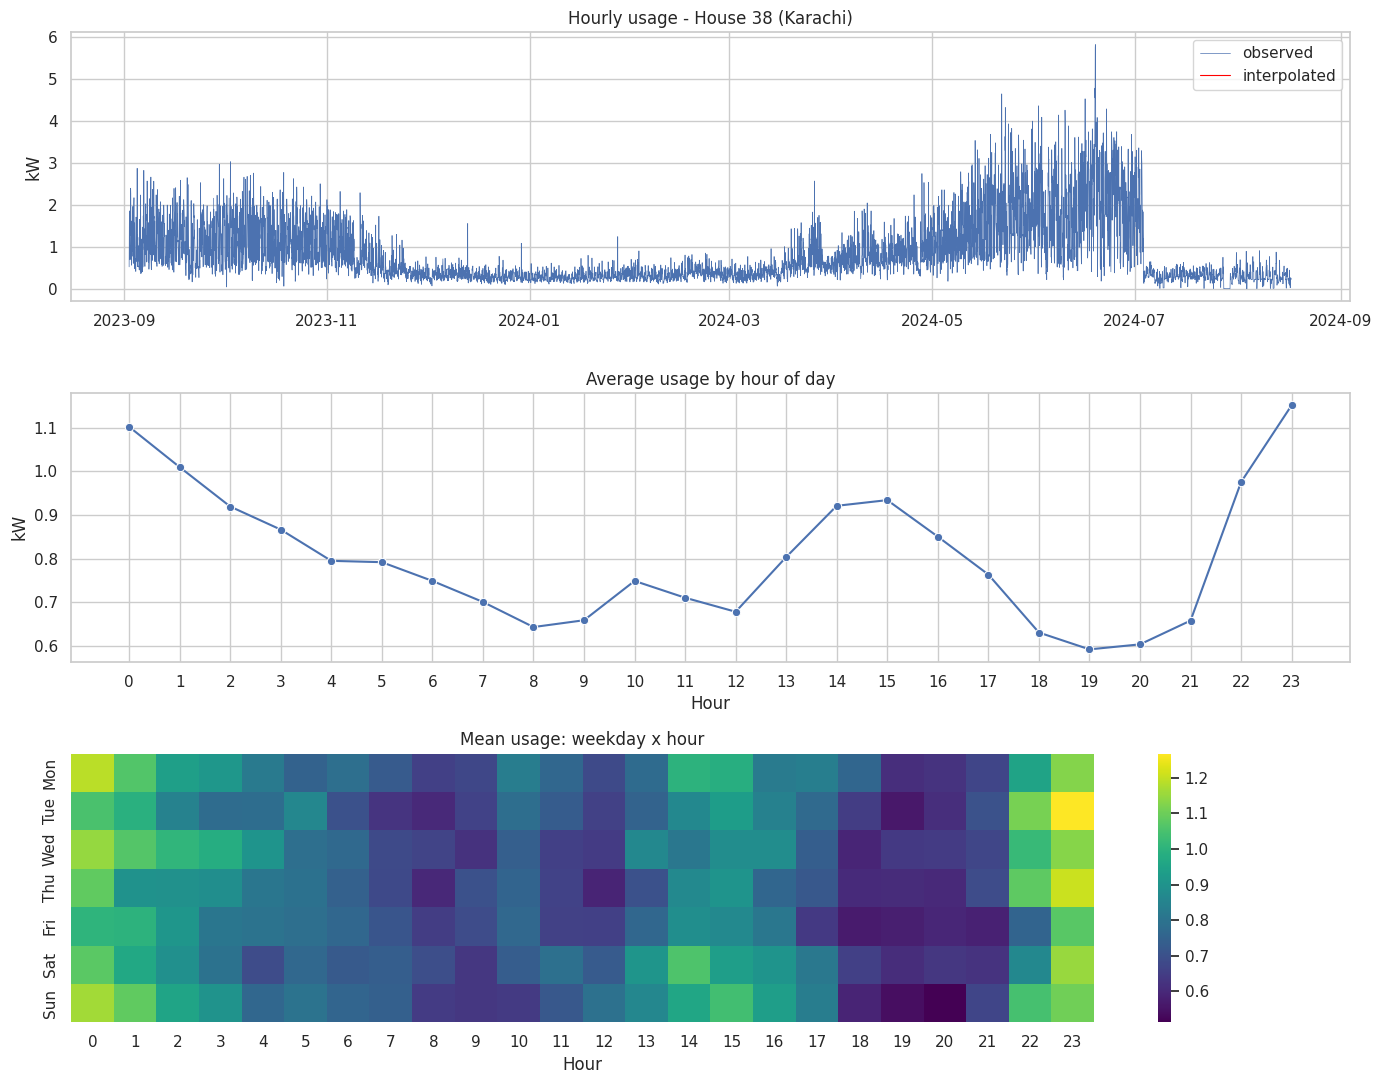

In [6]:
fig, axes = plt.subplots(3, 1, figsize=(14, 11))

axes[0].plot(h38.index, h38["Usage (kW)"].where(h38["observed"]), lw=0.5, label="observed")
axes[0].plot(h38.index, h38["Usage (kW)"].where(~h38["observed"]), lw=0.8, color="red", label="interpolated")
axes[0].set(title="Hourly usage - House 38 (Karachi)", ylabel="kW"); axes[0].legend()

avg_by_hour = h38.groupby(h38.index.hour)["Usage (kW)"].mean()
sns.lineplot(x=avg_by_hour.index, y=avg_by_hour.values, marker="o", ax=axes[1])
axes[1].set(title="Average usage by hour of day", xlabel="Hour", ylabel="kW", xticks=range(24))

pivot = (h38.assign(h=h38.index.hour, d=h38.index.dayofweek)
            .pivot_table(index="d", columns="h", values="Usage (kW)", aggfunc="mean"))
sns.heatmap(pivot, cmap="viridis", ax=axes[2], yticklabels=["Mon","Tue","Wed","Thu","Fri","Sat","Sun"])
axes[2].set(title="Mean usage: weekday x hour", xlabel="Hour", ylabel="")
plt.tight_layout(); plt.show()

## 3. Features, split, metrics

* All lag / rolling features use **past values only** (`shift(1)` before rolling) - the old `rolling(24)` included the hour being predicted.
* `month` is dropped: with ~1 year of data the test months were never seen in training, so trees cannot use it.
* Chronological split 70 / 10 / 20 (train / validation / test), identical for every model.

In [7]:
LAGS = [1, 2, 24, 48, 168]
CAL_FEATS     = ["hour", "dow", "is_weekend"]
HISTORY_FEATS = [f"lag_{l}" for l in LAGS] + ["roll_mean_24", "roll_std_24", "roll_mean_168"]
BASE_FEATURES = CAL_FEATS + HISTORY_FEATS
WEATHER_FEATURES = ["Temperature", "Humidity", "Wind Speed", "Solar Radiation"]


def add_features(hourly, weather=None):
    d = hourly.copy()
    if weather is not None:
        d = d.join(weather, how="left")
    s = d["Usage (kW)"]
    d["hour"] = d.index.hour
    d["dow"] = d.index.dayofweek
    d["is_weekend"] = (d["dow"] >= 5).astype(int)
    for l in LAGS:
        d[f"lag_{l}"] = s.shift(l)
    past = s.shift(1)                                   # <- no leakage of current hour
    d["roll_mean_24"]  = past.rolling(24,  min_periods=18).mean()
    d["roll_std_24"]   = past.rolling(24,  min_periods=18).std()
    d["roll_mean_168"] = past.rolling(168, min_periods=120).mean()
    d["y"] = s
    return d


def split_times(index, train_frac=0.7, val_frac=0.1):
    n = len(index)
    return index[int(n * train_frac)], index[int(n * (train_frac + val_frac))]


def make_splits(d, features):
    """Train/val/test using only observed target hours with complete features."""
    usable = d[d["observed"]].dropna(subset=features + ["y"])
    t1, t2 = split_times(d.index)
    return (usable[usable.index < t1],
            usable[(usable.index >= t1) & (usable.index < t2)],
            usable[usable.index >= t2], (t1, t2))


def smape(a, p):
    a, p = np.asarray(a, float), np.asarray(p, float)
    return 100 * np.mean(2 * np.abs(a - p) / (np.abs(a) + np.abs(p) + 1e-8))


def score(y, p, naive):
    mae = mean_absolute_error(y, p)
    return {"MAE (kW)": mae,
            "RMSE (kW)": np.sqrt(mean_squared_error(y, p)),
            "sMAPE (%)": smape(y, p),
            "Skill vs naive-24h": 1 - mae / mean_absolute_error(y, naive)}   # >0 beats seasonal-naive


def results_table(preds, y, naive):
    """Score every model on the exact same rows."""
    common = y.index
    for p in preds.values():
        common = common.intersection(p.index)
    rows = {name: score(y.loc[common], p.loc[common], naive.loc[common]) for name, p in preds.items()}
    return pd.DataFrame(rows).T.round(4), common


def make_rf():
    return RandomForestRegressor(n_estimators=300, min_samples_leaf=3, max_features=0.5,
                                 n_jobs=-1, random_state=SEED)

def make_hgb():
    return HistGradientBoostingRegressor(max_iter=300, learning_rate=0.05, random_state=SEED)

## 4. Forecasting: baselines vs ML models (House 38)

A model only matters if it beats the trivial baselines (*same hour yesterday*, *same hour last week*).

In [8]:
d38 = add_features(h38)
tr, va, te, (t1, t2) = make_splits(d38, BASE_FEATURES)
print(f"train {len(tr)} | val {len(va)} | test {len(te)}")
print(f"train: {tr.index.min():%Y-%m-%d} -> {tr.index.max():%Y-%m-%d}")
print(f"test : {te.index.min():%Y-%m-%d} -> {te.index.max():%Y-%m-%d}")

rf  = make_rf().fit(tr[BASE_FEATURES], tr["y"])
hgb = make_hgb().fit(tr[BASE_FEATURES], tr["y"])

preds = {
    "Persistence (t-1h)":     te["lag_1"],
    "Seasonal naive (t-24h)": te["lag_24"],
    "Seasonal naive (t-168h)":te["lag_168"],
    "Random Forest":          pd.Series(rf.predict(te[BASE_FEATURES]),  index=te.index),
    "HistGradientBoosting":   pd.Series(hgb.predict(te[BASE_FEATURES]), index=te.index),
}

train 5706 | val 839 | test 1679
train: 2023-09-09 -> 2024-05-04
test : 2024-06-08 -> 2024-08-17


In [9]:
lgbm = LGBMRegressor(n_estimators=300, learning_rate=0.05,
                     random_state=SEED, n_jobs=-1, verbose=-1)
lgbm.fit(tr[BASE_FEATURES], tr["y"])
preds["LightGBM"] = pd.Series(lgbm.predict(te[BASE_FEATURES]), index=te.index)

In [10]:
delta_target = tr["y"] - tr["lag_1"]          # change from last hour

lgbm_d = LGBMRegressor(n_estimators=300, learning_rate=0.05,
                       random_state=SEED, n_jobs=-1, verbose=-1)
lgbm_d.fit(tr[BASE_FEATURES], delta_target)
preds["LightGBM (delta)"] = pd.Series(
    te["lag_1"].values + lgbm_d.predict(te[BASE_FEATURES]), index=te.index)

rf_d = make_rf().fit(tr[BASE_FEATURES], delta_target)
preds["RF (delta)"] = pd.Series(
    te["lag_1"].values + rf_d.predict(te[BASE_FEATURES]), index=te.index)

### LSTM (same test rows, train-only scaling, early stopping)

I0000 00:00:1792508580.142784     117 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1792508580.146995     117 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


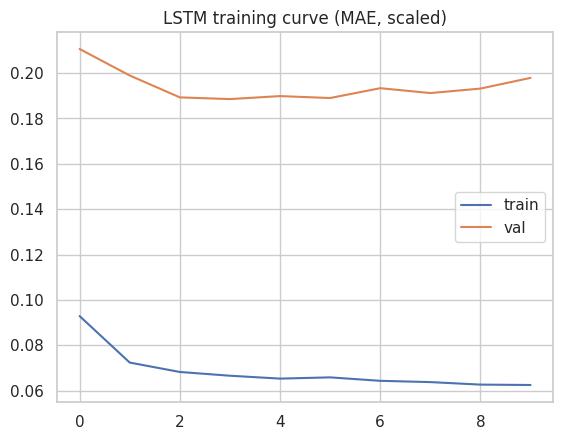

In [11]:
SEQ_LEN = 24
LSTM_COLS = ["Usage (kW)", "hour_sin", "hour_cos", "dow_sin", "dow_cos"]

def add_cyclical(d):
    d = d.copy()
    d["hour_sin"] = np.sin(2 * np.pi * d.index.hour / 24);      d["hour_cos"] = np.cos(2 * np.pi * d.index.hour / 24)
    d["dow_sin"]  = np.sin(2 * np.pi * d.index.dayofweek / 7);  d["dow_cos"]  = np.cos(2 * np.pi * d.index.dayofweek / 7)
    return d

def build_windows(d, cols, scaler, seq_len=SEQ_LEN):
    arr = scaler.transform(d[cols])                      # NaN preserved
    obs = d["observed"].values
    X, y, idx = [], [], []
    for i in range(seq_len, len(arr)):
        w = arr[i - seq_len:i]
        if obs[i] and not np.isnan(w).any() and not np.isnan(arr[i, 0]):
            X.append(w); y.append(arr[i, 0]); idx.append(d.index[i])
    return np.array(X), np.array(y), pd.DatetimeIndex(idx)

def run_lstm(d, t1, t2, epochs=60):
    d = add_cyclical(d)
    scaler = MinMaxScaler().fit(d.loc[d.index < t1, LSTM_COLS].dropna())      # train only
    X, y, idx = build_windows(d, LSTM_COLS, scaler)
    m_tr, m_va, m_te = idx < t1, (idx >= t1) & (idx < t2), idx >= t2

    model = tf.keras.Sequential([
        tf.keras.layers.Input(shape=(SEQ_LEN, len(LSTM_COLS))),
        tf.keras.layers.LSTM(64, return_sequences=True),
        tf.keras.layers.Dropout(0.2),
        tf.keras.layers.LSTM(32),
        tf.keras.layers.Dense(16, activation="relu"),
        tf.keras.layers.Dense(1),
    ])
    model.compile(optimizer=tf.keras.optimizers.Adam(1e-3), loss="mae")
    hist = model.fit(X[m_tr], y[m_tr], validation_data=(X[m_va], y[m_va]), epochs=epochs,
                     batch_size=64, verbose=0,
                     callbacks=[tf.keras.callbacks.EarlyStopping(patience=6, restore_best_weights=True)])
    lo, hi = scaler.data_min_[0], scaler.data_max_[0]
    pred = model.predict(X[m_te], verbose=0).ravel() * (hi - lo) + lo
    return pd.Series(pred, index=idx[m_te]), hist

if HAS_TF:
    preds["LSTM (24h window)"], lstm_hist = run_lstm(d38, t1, t2)
    plt.plot(lstm_hist.history["loss"], label="train"); plt.plot(lstm_hist.history["val_loss"], label="val")
    plt.title("LSTM training curve (MAE, scaled)"); plt.legend(); plt.show()

All models scored on the same 1679 test hours



,MAE (kW),RMSE (kW),sMAPE (%),Skill vs naive-24h
Persistence (t-1h),0.2732,0.5066,28.4918,0.3354
RF (delta),0.2937,0.4997,38.2417,0.2853
LightGBM (delta),0.3217,0.5632,39.0855,0.2174
Random Forest,0.3401,0.5945,41.1173,0.1725
LSTM (24h window),0.3573,0.5967,44.6685,0.1307
HistGradientBoosting,0.3727,0.6706,42.5263,0.0932
LightGBM,0.3732,0.6713,42.8874,0.0921
Seasonal naive (t-24h),0.4110,0.6936,51.5871,0.0000
Seasonal naive (t-168h),0.5806,0.9372,64.7626,-0.4128


Best ML model: RF (delta)


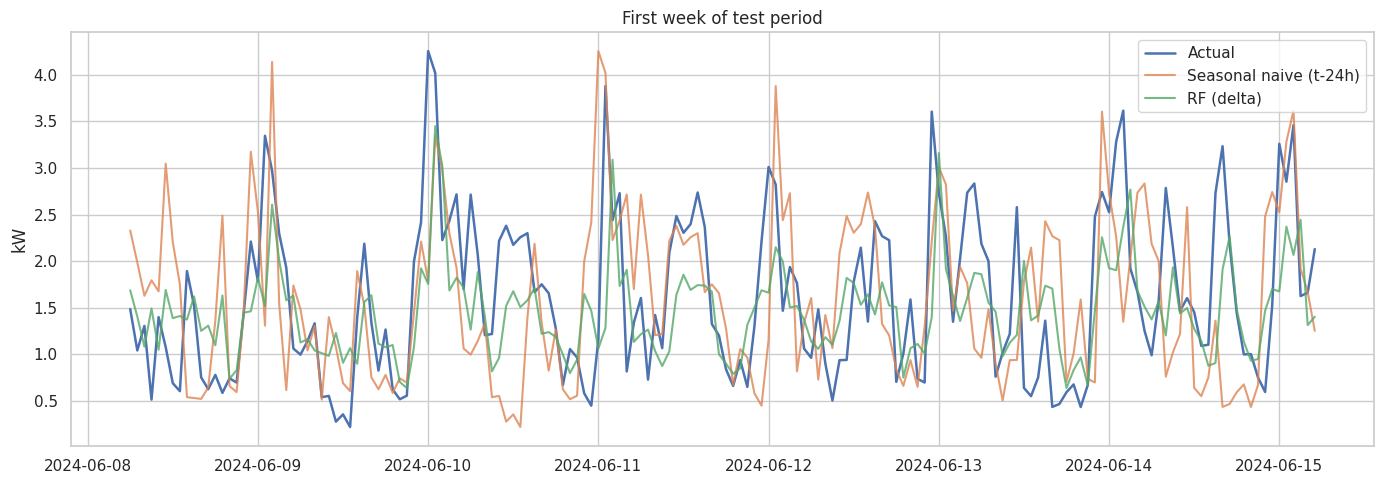

In [12]:
table, common = results_table(preds, te["y"], te["lag_24"])
print(f"All models scored on the same {len(common)} test hours\n")
display(table.sort_values("MAE (kW)"))

best_name = table.drop(index=[i for i in table.index if "naive" in i or "Persistence" in i])["MAE (kW)"].idxmin()
print("Best ML model:", best_name)

n = 24 * 7
plt.figure(figsize=(14, 5))
plt.plot(common[:n], te["y"].loc[common][:n], label="Actual", lw=1.8)
for name in ["Seasonal naive (t-24h)", best_name]:
    plt.plot(common[:n], preds[name].loc[common][:n], label=name, alpha=0.8)
plt.title("First week of test period"); plt.ylabel("kW"); plt.legend(); plt.tight_layout(); plt.show()

In [13]:
DAY_AHEAD = ["hour", "dow", "is_weekend", "lag_24", "lag_48", "lag_168"]

rf_da = make_rf().fit(tr[DAY_AHEAD], tr["y"])
lgbm_da = LGBMRegressor(n_estimators=300, learning_rate=0.05,
                        random_state=SEED, n_jobs=-1, verbose=-1)
lgbm_da.fit(tr[DAY_AHEAD], tr["y"])

preds_da = {
    "Seasonal naive (t-24h)":  te["lag_24"],
    "Seasonal naive (t-168h)": te["lag_168"],
    "RF (day-ahead)":       pd.Series(rf_da.predict(te[DAY_AHEAD]),   index=te.index),
    "LightGBM (day-ahead)": pd.Series(lgbm_da.predict(te[DAY_AHEAD]), index=te.index),
}
table_da, _ = results_table(preds_da, te["y"], te["lag_24"])
display(table_da.sort_values("MAE (kW)"))

,MAE (kW),RMSE (kW),sMAPE (%),Skill vs naive-24h
Seasonal naive (t-24h),0.4110,0.6936,51.5871,0.0000
RF (day-ahead),0.4284,0.6899,50.6926,-0.0425
LightGBM (day-ahead),0.4446,0.7311,51.2526,-0.0818
Seasonal naive (t-168h),0.5806,0.9372,64.7626,-0.4128


In [14]:
delta_da = tr["y"] - tr["lag_24"]          # change from same hour yesterday

rf_da_d = make_rf().fit(tr[DAY_AHEAD], delta_da)
lgbm_da_d = LGBMRegressor(n_estimators=300, learning_rate=0.05,
                          random_state=SEED, n_jobs=-1, verbose=-1)
lgbm_da_d.fit(tr[DAY_AHEAD], delta_da)

preds_da["RF (day-ahead, delta)"] = pd.Series(
    te["lag_24"].values + rf_da_d.predict(te[DAY_AHEAD]), index=te.index)
preds_da["LightGBM (day-ahead, delta)"] = pd.Series(
    te["lag_24"].values + lgbm_da_d.predict(te[DAY_AHEAD]), index=te.index)

table_da, _ = results_table(preds_da, te["y"], te["lag_24"])
display(table_da.sort_values("MAE (kW)"))

,MAE (kW),RMSE (kW),sMAPE (%),Skill vs naive-24h
"RF (day-ahead, delta)",0.3908,0.6352,48.6014,0.0490
Seasonal naive (t-24h),0.4110,0.6936,51.5871,0.0000
"LightGBM (day-ahead, delta)",0.4115,0.6732,50.1124,-0.0011
RF (day-ahead),0.4284,0.6899,50.6926,-0.0425
LightGBM (day-ahead),0.4446,0.7311,51.2526,-0.0818
Seasonal naive (t-168h),0.5806,0.9372,64.7626,-0.4128


In [15]:
def compare_house_new(path):
    hourly, rep = load_house(path)
    d = add_features(hourly)
    tr, va, te, _ = make_splits(d, BASE_FEATURES)
    out = {"test_hours": len(te), "pct_observed": rep["pct_observed"]}

    # 1 hour ahead
    out["persist_1h"] = mean_absolute_error(te["y"], te["lag_1"])
    m = make_rf().fit(tr[BASE_FEATURES], tr["y"] - tr["lag_1"])
    out["rf_delta_1h"] = mean_absolute_error(
        te["y"], te["lag_1"] + m.predict(te[BASE_FEATURES]))

    # 1 day ahead
    out["naive_24h"] = mean_absolute_error(te["y"], te["lag_24"])
    m = make_rf().fit(tr[DAY_AHEAD], tr["y"] - tr["lag_24"])
    out["rf_delta_24h"] = mean_absolute_error(
        te["y"], te["lag_24"] + m.predict(te[DAY_AHEAD]))
    return out

In [16]:
rows = []
for city, nums in HOUSES.items():
    for n in nums:
        name = f"{city}_{n}"
        try:
            rows.append({"house": name, "city": city, **compare_house_new(house_path(city, n))})
            print("done:", name)
        except Exception as e:
            print(f"[{name}] FAILED: {e}")

res = pd.DataFrame(rows)
res["skill_1h"]  = 1 - res["rf_delta_1h"]  / res["persist_1h"]
res["skill_24h"] = 1 - res["rf_delta_24h"] / res["naive_24h"]
display(res.round(4))
print(res.groupby("city")[["skill_1h", "skill_24h"]].mean().round(3))
print("\nAverage skill - 1h:", res["skill_1h"].mean().round(3),
      "| 24h:", res["skill_24h"].mean().round(3))

done: Karachi_38
done: Karachi_39
done: Karachi_40
done: Lahore_7
done: Lahore_8
done: Lahore_9
done: Peshawar_26
done: Peshawar_29
done: Peshawar_30
done: Multan_18
done: Multan_19
done: Multan_20
done: Skardu_56
done: Skardu_57
done: Skardu_59
done: Islamabad_48
done: Islamabad_49
done: Islamabad_50


,house,city,test_hours,pct_observed,persist_1h,rf_delta_1h,naive_24h,rf_delta_24h,skill_1h,skill_24h
0,Karachi_38,Karachi,1679,99.9881,0.2732,0.2937,0.4110,0.3908,-0.0753,0.0490
1,Karachi_39,Karachi,1757,99.6926,0.4226,0.3823,0.4612,0.3844,0.0952,0.1665
2,Karachi_40,Karachi,1747,99.2446,0.3534,0.3466,0.4912,0.4882,0.0192,0.0061
3,Lahore_7,Lahore,1014,71.0041,0.2611,0.2545,0.3904,0.3431,0.0256,0.1213
4,Lahore_8,Lahore,1753,97.8082,0.3183,0.2941,0.4957,0.4510,0.0759,0.0902
5,Lahore_9,Lahore,1458,98.5502,0.3825,0.3504,0.5098,0.4381,0.0839,0.1408
6,Peshawar_26,Peshawar,1248,94.5205,0.2677,0.2610,0.3552,0.3630,0.0248,-0.0218
7,Peshawar_29,Peshawar,1753,98.2877,0.1918,0.2490,0.3182,0.3334,-0.2979,-0.0476
8,Peshawar_30,Peshawar,1752,73.7215,1.3095,0.5980,0.7019,0.7340,0.5433,-0.0457
9,Multan_18,Multan,1752,99.9886,0.2491,0.2226,0.2866,0.2678,0.1061,0.0656


           skill_1h  skill_24h
city                          
Islamabad     0.036      0.022
Karachi       0.013      0.074
Lahore        0.062      0.117
Multan        0.081      0.082
Peshawar      0.090     -0.038
Skardu       -0.155      0.070

Average skill - 1h: 0.021 | 24h: 0.055


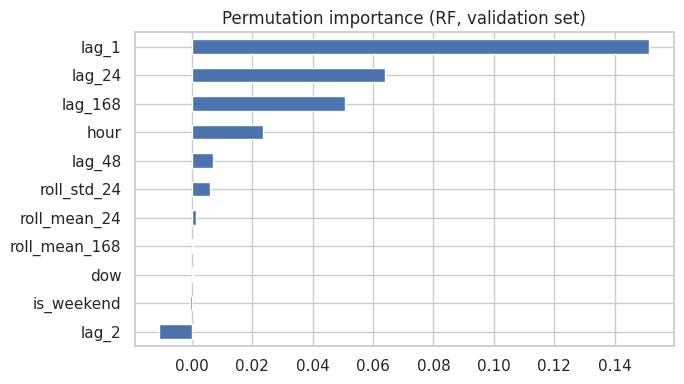

In [17]:
# Permutation importance on validation data (impurity importance is biased toward high-cardinality features)
pi = permutation_importance(rf, va[BASE_FEATURES], va["y"], n_repeats=5, random_state=SEED, n_jobs=-1)
pd.Series(pi.importances_mean, index=BASE_FEATURES).sort_values().plot.barh(figsize=(7, 4),
        title="Permutation importance (RF, validation set)")
plt.tight_layout(); plt.show()

## 5. Anomaly detection

Residual = actual − forecast. The threshold is a **robust z-score (median/MAD)** fitted on *validation* residuals (out-of-sample for the model, unlike train residuals) and then applied to the test period. Mean/std are inflated by the very outliers we want to find, so MAD is more reliable.

Anomalies: 13 / 1679 (0.77%)
type
spike    13


,actual,predicted,z,anomaly,type
datetime,,,,,
2024-06-19 02:00:00,5.740,1.588,6.545,True,spike
2024-06-19 03:00:00,5.816,1.790,6.337,True,spike
2024-06-19 04:00:00,5.788,1.767,6.329,True,spike
2024-06-19 05:00:00,4.600,1.590,4.668,True,spike
2024-06-19 00:00:00,4.778,1.837,4.553,True,spike
2024-06-19 01:00:00,4.546,1.792,4.247,True,spike
2024-06-16 01:00:00,4.524,1.819,4.166,True,spike
2024-06-22 12:00:00,4.284,1.636,4.072,True,spike
2024-06-10 00:00:00,4.255,1.812,3.735,True,spike


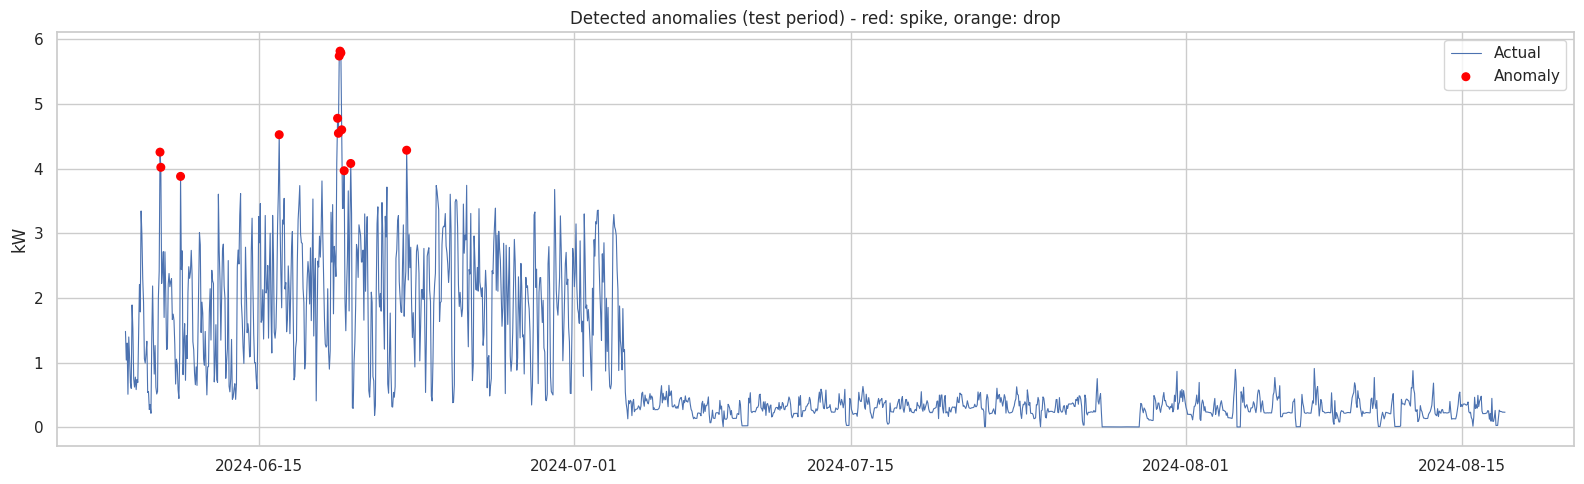

In [18]:
def detect_anomalies(model, features, va, te, k=3.5):
    res_va = va["y"].values - model.predict(va[features])
    med = np.median(res_va)
    sigma = 1.4826 * np.median(np.abs(res_va - med))        # robust std estimate
    pred = model.predict(te[features])
    z = (te["y"].values - pred - med) / sigma
    out = pd.DataFrame({"actual": te["y"], "predicted": pred, "z": z}, index=te.index)
    out["anomaly"] = np.abs(out["z"]) > k
    out["type"] = np.where(out["z"] > 0, "spike", "drop")
    return out

anom = detect_anomalies(rf, BASE_FEATURES, va, te)
print(f"Anomalies: {anom['anomaly'].sum()} / {len(anom)} ({anom['anomaly'].mean()*100:.2f}%)")
print(anom["type"][anom["anomaly"]].value_counts().to_string())
display(anom[anom["anomaly"]].sort_values("z", key=np.abs, ascending=False).head(10).round(3))

plt.figure(figsize=(16, 5))
plt.plot(anom.index, anom["actual"], lw=0.8, label="Actual")
a = anom[anom["anomaly"]]
plt.scatter(a.index, a["actual"], c=np.where(a["type"] == "spike", "red", "orange"), s=30, zorder=5, label="Anomaly")
plt.title("Detected anomalies (test period) - red: spike, orange: drop"); plt.ylabel("kW"); plt.legend()
plt.tight_layout(); plt.show()

In [19]:
def anomaly_diag(path):
    hourly, _ = load_house(path)
    d = add_features(hourly)
    tr, va, te, _ = make_splits(d, BASE_FEATURES)
    m = make_rf().fit(tr[BASE_FEATURES], tr["y"])
    r_va = va["y"].values - m.predict(va[BASE_FEATURES])
    r_te = te["y"].values - m.predict(te[BASE_FEATURES])
    mad = lambda r: 1.4826 * np.median(np.abs(r - np.median(r)))
    return {"val_median": np.median(r_va), "val_sigma": mad(r_va),
            "test_median": np.median(r_te), "test_sigma": mad(r_te),
            "val_mean_usage": va["y"].mean(), "test_mean_usage": te["y"].mean()}

for city, n in [("Skardu", 59), ("Multan", 20), ("Lahore", 8)]:
    out = anomaly_diag(house_path(city, n))
    print(city, n, {k: round(float(v), 3) for k, v in out.items()})

Skardu 59 {'val_median': -0.01, 'val_sigma': 0.013, 'test_median': -0.009, 'test_sigma': 0.043, 'val_mean_usage': 0.048, 'test_mean_usage': 0.092}
Multan 20 {'val_median': -0.038, 'val_sigma': 0.049, 'test_median': -0.042, 'test_sigma': 0.128, 'val_mean_usage': 0.23, 'test_mean_usage': 0.461}
Lahore 8 {'val_median': -0.038, 'val_sigma': 0.317, 'test_median': -0.061, 'test_sigma': 0.265, 'val_mean_usage': 1.885, 'test_mean_usage': 1.752}


In [20]:
def detect_anomalies_rel(model, features, va, te, k=3.5):
    eps = 0.1 * va["y"].mean()          # avoid dividing by ~0
    def rel(df):
        p = model.predict(df[features])
        return (df["y"].values - p) / (p + eps), p

    r_va, _ = rel(va)
    med = np.median(r_va)
    sigma = 1.4826 * np.median(np.abs(r_va - med))
    r_te, pred = rel(te)
    z = (r_te - med) / sigma

    out = pd.DataFrame({"actual": te["y"], "predicted": pred, "z": z}, index=te.index)
    out["anomaly"] = np.abs(out["z"]) > k
    out["type"] = np.where(out["z"] > 0, "spike", "drop")
    return out

In [21]:
def rate_compare(path):
    hourly, _ = load_house(path)
    d = add_features(hourly)
    tr, va, te, _ = make_splits(d, BASE_FEATURES)
    m = make_rf().fit(tr[BASE_FEATURES], tr["y"])
    old = detect_anomalies(m, BASE_FEATURES, va, te)["anomaly"].mean() * 100
    new = detect_anomalies_rel(m, BASE_FEATURES, va, te)["anomaly"].mean() * 100
    return round(old, 2), round(new, 2)

for city, n in [("Skardu", 59), ("Multan", 20), ("Skardu", 57),
                ("Skardu", 56), ("Lahore", 8), ("Karachi", 38)]:
    print(city, n, "(old %, new %):", rate_compare(house_path(city, n)))

Skardu 59 (old %, new %): (np.float64(37.05), np.float64(14.4))
Multan 20 (old %, new %): (np.float64(23.39), np.float64(7.93))
Skardu 57 (old %, new %): (np.float64(19.93), np.float64(7.78))
Skardu 56 (old %, new %): (np.float64(16.44), np.float64(8.85))
Lahore 8 (old %, new %): (np.float64(3.71), np.float64(2.22))
Karachi 38 (old %, new %): (np.float64(0.77), np.float64(0.3))


In [22]:
def rate_k(path, ks=(3.5, 5, 6, 8)):
    hourly, _ = load_house(path)
    d = add_features(hourly)
    tr, va, te, _ = make_splits(d, BASE_FEATURES)
    m = make_rf().fit(tr[BASE_FEATURES], tr["y"])
    return {k: round(detect_anomalies_rel(m, BASE_FEATURES, va, te, k=k)["anomaly"].mean() * 100, 2)
            for k in ks}

for city, n in [("Skardu", 59), ("Skardu", 56), ("Skardu", 57),
                ("Multan", 20), ("Lahore", 8), ("Karachi", 38)]:
    print(city, n, rate_k(house_path(city, n)))

Skardu 59 {3.5: np.float64(14.4), 5: np.float64(8.99), 6: np.float64(6.32), 8: np.float64(3.93)}
Skardu 56 {3.5: np.float64(8.85), 5: np.float64(4.34), 6: np.float64(2.37), 8: np.float64(0.87)}
Skardu 57 {3.5: np.float64(7.78), 5: np.float64(5.03), 6: np.float64(4.03), 8: np.float64(2.75)}
Multan 20 {3.5: np.float64(7.93), 5: np.float64(3.19), 6: np.float64(1.94), 8: np.float64(0.97)}
Lahore 8 {3.5: np.float64(2.22), 5: np.float64(1.03), 6: np.float64(0.63), 8: np.float64(0.11)}
Karachi 38 {3.5: np.float64(0.3), 5: np.float64(0.06), 6: np.float64(0.0), 8: np.float64(0.0)}


## 6. Does weather help? (Karachi)

Both models use exactly the same rows. Note: this uses **observed** weather at time *t*. In real deployment you would only have a weather *forecast*, so the gain here is an upper bound.

In [27]:
def load_weather(city):
    w = pd.read_csv(f"{WEATHER_ROOT}/{city}.csv")
    w["datetime"] = pd.to_datetime(w["datetime"], format="mixed")
    w = w.drop_duplicates("datetime").set_index("datetime").sort_index()
    return w[WEATHER_FEATURES].resample("h").mean()
    
def weather_both(city, n):
    hourly, _ = load_house(house_path(city, n))
    d = add_features(hourly, weather=load_weather(city))
    feats_w = DAY_AHEAD + WEATHER_FEATURES
    tr, va, te, _ = make_splits(d, feats_w)

    m0 = DeltaRF("lag_24").fit(tr[DAY_AHEAD], tr["y"])
    m1 = DeltaRF("lag_24").fit(tr[feats_w],   tr["y"])

    def gain(df):
        a = mean_absolute_error(df["y"], m0.predict(df[DAY_AHEAD]))
        b = mean_absolute_error(df["y"], m1.predict(df[feats_w]))
        return 100 * (a - b) / a          # positive = weather helps

    return {"val_gain_pct": gain(va), "test_gain_pct": gain(te)}


rows = [{"house": f"{c}_{n}", "city": c, **weather_both(c, n)}
        for c, nums in HOUSES.items() for n in nums]
wb = pd.DataFrame(rows)
wb["agree"] = (wb["val_gain_pct"] > 0) == (wb["test_gain_pct"] > 0)
display(wb.round(2).sort_values("val_gain_pct", ascending=False).reset_index(drop=True))

print("Validation and test agree on direction:", int(wb["agree"].sum()), "/", len(wb))
print("Weather helps on BOTH:", int(((wb.val_gain_pct > 0) & (wb.test_gain_pct > 0)).sum()))
print("Rule 'use weather if val_gain > 0' -> mean test gain:",
      wb.loc[wb.val_gain_pct > 0, "test_gain_pct"].mean().round(2), "%")

,house,city,val_gain_pct,test_gain_pct,agree
0,Lahore_7,Lahore,6.06,-3.30,False
1,Peshawar_30,Peshawar,6.04,5.28,True
2,Lahore_8,Lahore,5.36,4.47,True
3,Peshawar_29,Peshawar,3.83,-7.05,False
4,Lahore_9,Lahore,3.75,2.47,True
5,Islamabad_48,Islamabad,3.30,5.56,True
6,Multan_19,Multan,3.00,2.69,True
7,Karachi_38,Karachi,2.13,-19.02,False
8,Islamabad_49,Islamabad,1.91,-4.12,False
9,Skardu_59,Skardu,1.10,-0.01,False


Validation and test agree on direction: 12 / 18
Weather helps on BOTH: 7
Rule 'use weather if val_gain > 0' -> mean test gain: -0.65 %


## 7. All houses

Raw MAE is not comparable across houses. Reported here: **nMAE** (day-ahead MAE ÷ mean usage), and **skill** versus the matching baseline (1 = perfect, 0 = no better than the baseline, < 0 = worse): persistence for 1 hour ahead, seasonal naive (t-24h) for 1 day ahead. Anomaly rate uses the relative-residual detector with k = 5.

In [26]:
class DeltaRF:
    """RandomForest that predicts the change from a base lag and adds it back."""
    def __init__(self, base):
        self.base, self.model = base, make_rf()
    def fit(self, X, y):
        self.model.fit(X, y - X[self.base]); return self
    def predict(self, X):
        return X[self.base].values + self.model.predict(X)


def evaluate_house(path, k=5):
    hourly, rep = load_house(path)
    d = add_features(hourly)
    tr, va, te, _ = make_splits(d, BASE_FEATURES)
    y = te["y"]

    m1  = DeltaRF("lag_1").fit(tr[BASE_FEATURES], tr["y"])     # 1 hour ahead
    m24 = DeltaRF("lag_24").fit(tr[DAY_AHEAD], tr["y"])        # 1 day ahead
    rf  = make_rf().fit(tr[BASE_FEATURES], tr["y"])            # for anomalies

    mae_p1  = mean_absolute_error(y, te["lag_1"])
    mae_m1  = mean_absolute_error(y, m1.predict(te[BASE_FEATURES]))
    mae_n24 = mean_absolute_error(y, te["lag_24"])
    mae_m24 = mean_absolute_error(y, m24.predict(te[DAY_AHEAD]))
    an = detect_anomalies_rel(rf, BASE_FEATURES, va, te, k=k)

    return {"test_hours": len(te), "pct_observed": rep["pct_observed"],
            "nmae_24h": mae_m24 / y.mean(),
            "skill_1h": 1 - mae_m1 / mae_p1,
            "skill_24h": 1 - mae_m24 / mae_n24,
            "anomaly_pct": 100 * an["anomaly"].mean()}


records, failures = [], {}
for city, nums in HOUSES.items():
    for n in nums:
        name = f"{city}_{n}"
        try:
            records.append({"house": name, "city": city, **evaluate_house(house_path(city, n))})
            print("done:", name)
        except Exception as e:
            failures[name] = f"{type(e).__name__}: {e}"

summary = pd.DataFrame(records)
display(summary.sort_values("skill_24h", ascending=False).round(3).reset_index(drop=True))
if failures:
    print("FAILED houses:"); [print(" ", k, "->", v) for k, v in failures.items()]

done: Karachi_38
done: Karachi_39
done: Karachi_40
done: Lahore_7
done: Lahore_8
done: Lahore_9
done: Peshawar_26
done: Peshawar_29
done: Peshawar_30
done: Multan_18
done: Multan_19
done: Multan_20
done: Skardu_56
done: Skardu_57
done: Skardu_59
done: Islamabad_48
done: Islamabad_49
done: Islamabad_50


,house,city,test_hours,pct_observed,nmae_24h,skill_1h,skill_24h,anomaly_pct
0,Karachi_39,Karachi,1757,99.693,0.463,0.095,0.166,0.683
1,Islamabad_50,Islamabad,645,87.422,0.477,0.159,0.158,0.000
2,Lahore_9,Lahore,1458,98.550,0.484,0.084,0.141,1.029
3,Multan_20,Multan,1753,99.737,0.355,0.053,0.131,3.195
4,Lahore_7,Lahore,1014,71.004,0.428,0.026,0.121,2.071
5,Skardu_59,Skardu,1757,90.292,0.760,-0.239,0.120,8.993
6,Lahore_8,Lahore,1753,97.808,0.257,0.076,0.090,1.027
7,Multan_18,Multan,1752,99.989,0.272,0.106,0.066,1.598
8,Multan_19,Multan,1169,89.155,0.381,0.085,0.051,1.540
9,Karachi_38,Karachi,1679,99.988,0.432,-0.075,0.049,0.060


,nmae_24h,skill_1h,skill_24h,anomaly_pct,pct_observed
city,,,,,
Multan,0.336,0.081,0.082,2.111,96.294
Lahore,0.390,0.062,0.117,1.376,89.121
Karachi,0.424,0.013,0.074,0.705,99.642
Islamabad,0.476,0.036,0.022,1.026,94.312
Peshawar,0.505,0.090,-0.038,1.879,88.843
Skardu,0.939,-0.155,0.070,6.121,87.027


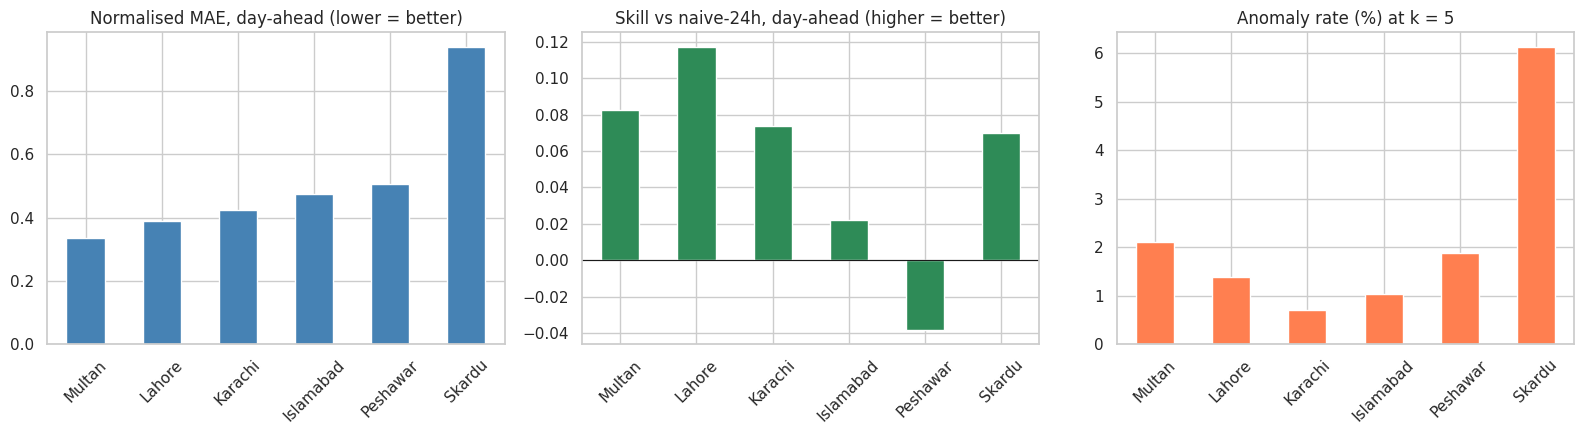

In [28]:
if len(summary):
    city_avg = (summary.groupby("city")[["nmae_24h", "skill_1h", "skill_24h", "anomaly_pct", "pct_observed"]]
                .mean().sort_values("nmae_24h"))
    display(city_avg.round(3))

    fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
    city_avg["nmae_24h"].plot.bar(ax=axes[0], color="steelblue", title="Normalised MAE, day-ahead (lower = better)")
    city_avg["skill_24h"].plot.bar(ax=axes[1], color="seagreen", title="Skill vs naive-24h, day-ahead (higher = better)")
    city_avg["anomaly_pct"].plot.bar(ax=axes[2], color="coral", title="Anomaly rate (%) at k = 5")
    for ax in axes: ax.tick_params(axis="x", rotation=45); ax.set_xlabel("")
    axes[1].axhline(0, color="k", lw=0.8)
    plt.tight_layout(); plt.show()

## 8. Next steps

* **Forecast horizon:** everything above is 1-hour-ahead using `lag_1`. Real use-cases (billing, load planning) usually need day-ahead; re-run with `lag_1`/`lag_2` removed and the target shifted by 24 h.
* **Rolling-origin CV** (`TimeSeriesSplit`) instead of one test window - the current test set is only the last ~2 months (summer), so results are season-specific.
* **Holidays / Ramadan / load-shedding** flags are likely strong drivers in Pakistan.
* **Appliance columns** (AC, fridge, kitchen...) are loaded but unused - useful for disaggregation or per-appliance anomaly detection.
* **Sensor-downtime anomalies:** the downtime mask is a good starting point for a separate "data-quality" detector, distinct from consumption anomalies.

In [ ]:
print("test:", te.index.min().date(), "->", te.index.max().date())

In [32]:
hol = pd.to_datetime(["2024-06-17", "2024-06-18", "2024-06-19",   # Eid ul Adha (verify)
                      "2024-07-16", "2024-07-17",                 # Ashura (verify)
                      "2024-08-14"])                              # Independence Day

hourly, _ = load_house(house_path("Karachi", 38))
d = add_features(hourly)
tr, va, te, _ = make_splits(d, BASE_FEATURES)
rf = make_rf().fit(tr[BASE_FEATURES], tr["y"])
an = detect_anomalies_rel(rf, BASE_FEATURES, va, te, k=5)

flagged = an[an["anomaly"]]
on_hol = flagged.index.normalize().isin(hol)
print("Flagged anomalies:", len(flagged), "| on public holidays:", int(on_hol.sum()))
display(flagged[on_hol].round(3))

Flagged anomalies: 1 | on public holidays: 1


,actual,predicted,z,anomaly,type
datetime,,,,,
2024-06-19 02:00:00,5.74,1.588,5.604,True,spike


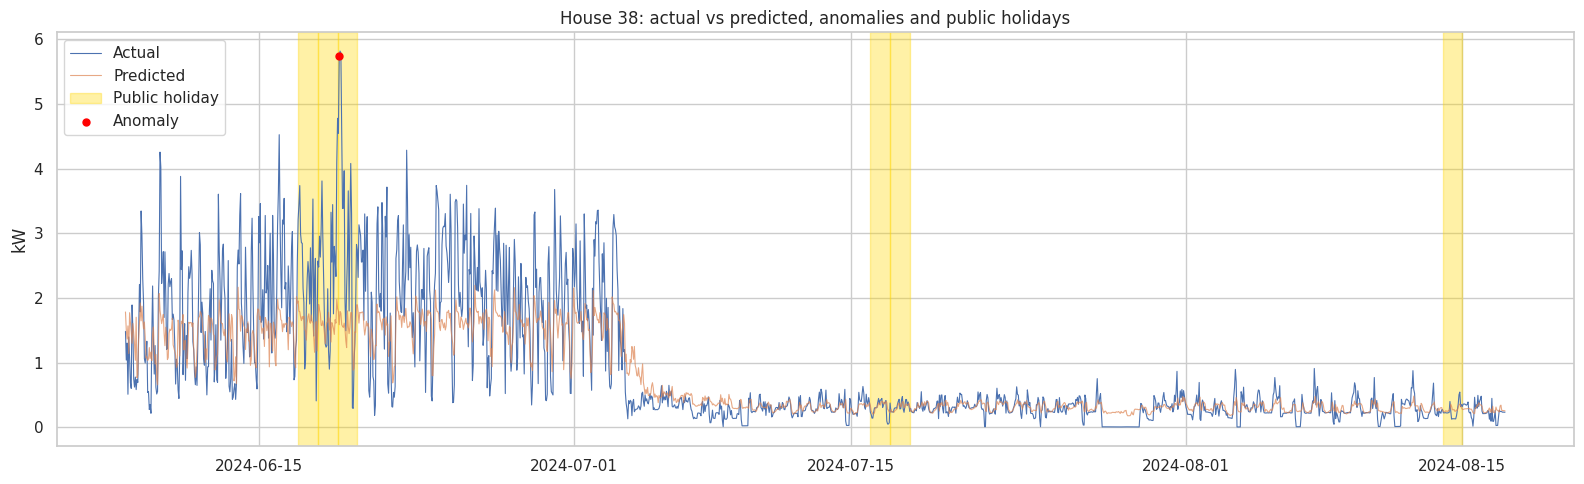

In [33]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(16, 5))
ax.plot(an.index, an["actual"], lw=0.8, label="Actual")
ax.plot(an.index, an["predicted"], lw=0.8, alpha=0.7, label="Predicted")

# shade holidays (each date = one full day)
for i, day in enumerate(hol):
    ax.axvspan(day, day + pd.Timedelta(days=1), color="gold", alpha=0.35,
               label="Public holiday" if i == 0 else None)

# detected anomalies
fl = an[an["anomaly"]]
ax.scatter(fl.index, fl["actual"], color="red", s=25, zorder=5, label="Anomaly")

ax.set_title("House 38: actual vs predicted, anomalies and public holidays")
ax.set_ylabel("kW"); ax.legend(); plt.tight_layout(); plt.show()

In [34]:
import os, json
import joblib

os.makedirs("artifacts", exist_ok=True)

In [37]:
meta = []  

for city in HOUSES:                 
    for n in HOUSES[city]:         
        name = city + "_" + str(n)  

        # 1) data load and features
        hourly, rep = load_house(house_path(city, n))
        d = add_features(hourly)
        tr, va, te, _ = make_splits(d, BASE_FEATURES)

        # 2) models train
        rf  = make_rf().fit(tr[BASE_FEATURES], tr["y"])      
        m24 = DeltaRF("lag_24").fit(tr[DAY_AHEAD], tr["y"])    

        # 3) anomaly table (k=5) and forecast column
        result = detect_anomalies_rel(rf, BASE_FEATURES, va, te, k=5)
        result = result[["actual", "predicted", "z"]]
        result["forecast_24h"] = m24.predict(te[DAY_AHEAD])

        # 4) Generate CSV file 
        result.round(4).to_csv("artifacts/" + name + ".csv")

        meta.append({"house": name, "city": city,
                     "test_hours": len(te), "pct_observed": round(rep["pct_observed"], 1)})
        print("saved:", name)

with open("artifacts/meta.json", "w") as f:
    json.dump(meta, f, indent=2)

saved: Karachi_38
saved: Karachi_39
saved: Karachi_40
saved: Lahore_7
saved: Lahore_8
saved: Lahore_9
saved: Peshawar_26
saved: Peshawar_29
saved: Peshawar_30
saved: Multan_18
saved: Multan_19
saved: Multan_20
saved: Skardu_56
saved: Skardu_57
saved: Skardu_59
saved: Islamabad_48
saved: Islamabad_49
saved: Islamabad_50


In [38]:
hourly, _ = load_house(house_path("Karachi", 38))
d = add_features(hourly)
tr, va, te, _ = make_splits(d, BASE_FEATURES)

# models train
m24 = DeltaRF("lag_24").fit(tr[DAY_AHEAD], tr["y"])
rf  = make_rf().fit(tr[BASE_FEATURES], tr["y"])

# anomaly ke numbers (validation se)
pred_val = rf.predict(va[BASE_FEATURES])
eps = 0.1 * va["y"].mean()
r = (va["y"].values - pred_val) / (pred_val + eps)
median = float(np.median(r))
sigma = float(1.4826 * np.median(np.abs(r - median)))

# save
joblib.dump({"model": m24, "features": DAY_AHEAD}, "artifacts/karachi_38_dayahead.joblib", compress=3)
joblib.dump({"model": rf, "features": BASE_FEATURES, "eps": float(eps),
             "median": median, "sigma": sigma, "k_default": 5},
            "artifacts/karachi_38_anomaly.joblib", compress=3)
print("models saved")

models saved


In [39]:
config = {
    "target": "Usage (kW)",
    "split": {"train": 0.70, "val": 0.10, "test": 0.20},
    "base_features": BASE_FEATURES,
    "day_ahead_features": DAY_AHEAD,
    "lags": LAGS,
    "anomaly_k_default": 5,
}
with open("artifacts/feature_config.json", "w") as f:
    json.dump(config, f, indent=2)

for name in sorted(os.listdir("artifacts")):
    size_mb = os.path.getsize("artifacts/" + name) / 1e6
    print(name, round(size_mb, 2), "MB")

Islamabad_48.csv 0.08 MB
Islamabad_49.csv 0.07 MB
Islamabad_50.csv 0.03 MB
Karachi_38.csv 0.08 MB
Karachi_39.csv 0.08 MB
Karachi_40.csv 0.08 MB
Lahore_7.csv 0.05 MB
Lahore_8.csv 0.08 MB
Lahore_9.csv 0.07 MB
Multan_18.csv 0.08 MB
Multan_19.csv 0.06 MB
Multan_20.csv 0.08 MB
Peshawar_26.csv 0.06 MB
Peshawar_29.csv 0.08 MB
Peshawar_30.csv 0.08 MB
Skardu_56.csv 0.08 MB
Skardu_57.csv 0.1 MB
Skardu_59.csv 0.08 MB
feature_config.json 0.0 MB
karachi_38_anomaly.joblib 15.08 MB
karachi_38_dayahead.joblib 14.95 MB
meta.json 0.0 MB
